### 1. Data Generation and Setup

We will generate synthetic data for 15 subjects across 3 tests. To ensure a high ICC, subjects will have widely different baseline abilities (high between-subject variance). To ensure a significant ANOVA result, we will introduce a small but consistent shift (difference) between the test scores (e.g., Test 3 scores are consistently higher than Test 1 and Test 2).

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
np.random.seed(42)

num_subjects = 15
# Subject baselines: large variance to guarantee a high ICC
subject_baselines = np.random.normal(loc=100, scale=15, size=num_subjects)

# Test effects: Test 3 has a slightly higher score than Test 1 and Test 2
test_effects = [0, 0, 5]

# Generate data with small residual error
data = []
for sub_idx, baseline in enumerate(subject_baselines):
    for test_idx, effect in enumerate(test_effects):
        # Small measurement error (low within-subject residual variance)
        error = np.random.normal(0, 1)
        score = baseline + effect + error
        data.append({
            'Subject': f'Sub_{sub_idx+1:02d}',
            'Test': f'Test_{test_idx+1}',
            'Score': score
        })

df = pd.DataFrame(data)
display(df.head(10))

,Subject,Test,Score
0,Sub_01,Test_1,106.888425
1,Sub_01,Test_2,106.437881
2,Sub_01,Test_3,112.764960
3,Sub_02,Test_1,97.018011
4,Sub_02,Test_2,96.513732
5,Sub_02,Test_3,104.391684
6,Sub_03,Test_1,109.489552
7,Sub_03,Test_2,109.782856
8,Sub_03,Test_3,113.290580
9,Sub_04,Test_1,122.301065


### 2. Repeated Measures ANOVA

Now we will perform a repeated measures ANOVA to see if there is a statistically significant difference between the three tests.

In [2]:
from statsmodels.stats.anova import AnovaRM

# Fit repeated measures ANOVA
aov = AnovaRM(df, depvar='Score', subject='Subject', within=['Test'])
res = aov.fit()
print(res)

               Anova
     F Value  Num DF  Den DF Pr > F
-----------------------------------
Test 133.5330 2.0000 28.0000 0.0000



### 3. Intra-class Correlation Coefficient (ICC)

We will calculate the ICC(3,1) (Two-way mixed effects, consistency, single rater/measurement model), which is highly relevant for within-subjects designs testing consistency across fixed raters/tests.

In [3]:
# To calculate ICC easily, we reshape the dataframe
df_wide = df.pivot(index='Subject', columns='Test', values='Score')

# Calculate mean squares to compute ICC manually
# ANOVA formulation: Total SS = SS_subjects + SS_tests + SS_error
grand_mean = df['Score'].mean()
n = num_subjects
k = 3

# Mean Square Subjects (MSBS)
subject_means = df.groupby('Subject')['Score'].mean()
MSBS = k * np.sum((subject_means - grand_mean)**2) / (n - 1)

# Mean Square Error (MSWE / MS_residual)
test_means = df.groupby('Test')['Score'].mean()
ss_total = np.sum((df['Score'] - grand_mean)**2)
ss_subjects = k * np.sum((subject_means - grand_mean)**2)
ss_tests = n * np.sum((test_means - grand_mean)**2)
ss_error = ss_total - ss_subjects - ss_tests
MS_error = ss_error / ((n - 1) * (k - 1))

# ICC(3,1) consistency formula: (MSBS - MS_error) / (MSBS + (k - 1) * MS_error)
icc_3_1 = (MSBS - MS_error) / (MSBS + (k - 1) * MS_error)

print(f"Intraclass Correlation Coefficient ICC(3,1): {icc_3_1:.4f}")

Intraclass Correlation Coefficient ICC(3,1): 0.9956


### 4. Plotting the Illustration

We'll plot the individual trajectories of each subject across the three tests. This visually demonstrates why both statements are true: the parallel trends (with Test 3 consistently higher) make the ANOVA highly significant, while the wide spread of subjects relative to the small differences between tests ensures a high ICC.

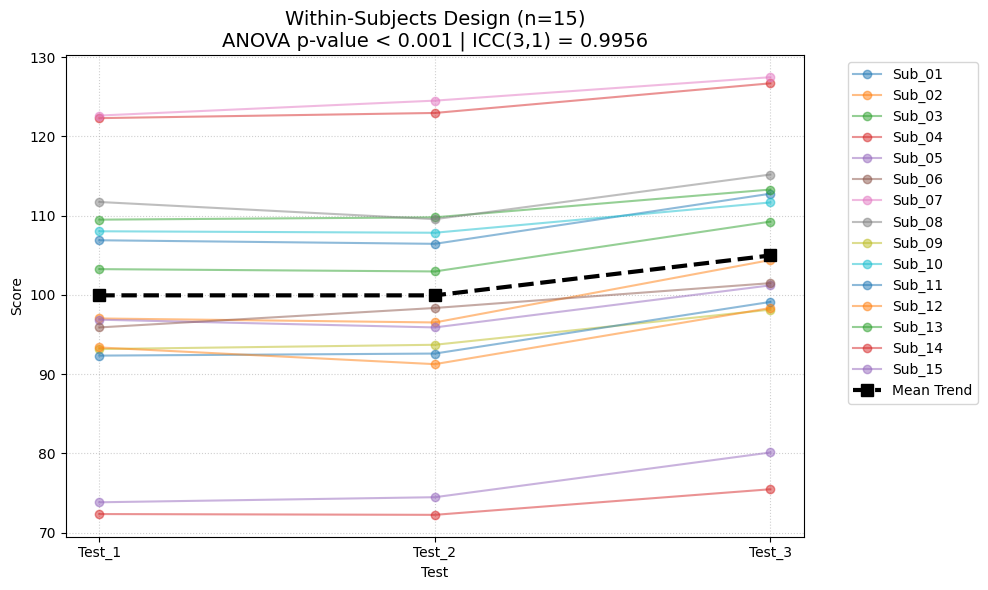

In [4]:
plt.figure(figsize=(10, 6))

# Plot individual lines for each subject
for subject in df['Subject'].unique():
    sub_data = df[df['Subject'] == subject]
    plt.plot(sub_data['Test'], sub_data['Score'], marker='o', alpha=0.5, label=subject)

# Plot the mean trend
mean_scores = df.groupby('Test')['Score'].mean()
plt.plot(mean_scores.index, mean_scores.values, color='black', linewidth=3, linestyle='--', marker='s', markersize=8, label='Mean Trend')

plt.title(f'Within-Subjects Design (n=15)\nANOVA p-value < 0.001 | ICC(3,1) = {icc_3_1:.4f}', fontsize=14)
plt.ylabel('Score')
plt.xlabel('Test')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()